In [20]:
#Assignment1-Q6
import numpy as np
import matplotlib.pyplot as plt
import random
import pandas as pd
from scipy import stats 
ns=100#num of sample
sd=np.random.randint(1,101,ns)
ts=4*sd+np.random.normal(0,1,ns)

df=pd.DataFrame({"StudyHour":sd,"TestScore":ts})
df

,StudyHour,TestScore
0,72,286.743977
1,38,151.954359
2,83,332.695624
3,18,71.656680
4,90,360.020200
...,...,...
95,16,63.881013
96,68,271.629781
97,61,245.610782
98,17,69.162489


In [21]:
x=df.StudyHour
y=df.TestScore
#print(x,y)

In [22]:
from sklearn.model_selection import train_test_split 

xtrain,xtest,ytrain,ytest=train_test_split(x,y,test_size=20,random_state=42)
print(xtrain.shape)
print(xtest.shape)

(80,)
(20,)


In [23]:
#model creationlinear regression predictions.csv
from sklearn import linear_model
lr = linear_model.LinearRegression()
xtrain=xtrain.values.reshape(80,1)
xtest=xtest.values.reshape(20,1)
#training
lr.fit(xtrain, ytrain)
#model testing
ypred=lr.predict(xtest)
print(ypred)
print(ytest)

[171.98622449 183.98512039 331.97150324 351.96966309 203.98328024
 187.98475236 195.9840163  247.9792319  135.98953677 287.97555159
  39.99836951 375.9674549  371.96782293 151.98806464 243.97959993
 359.96892703 295.97481552 103.99248101 343.97039915 395.96561475]
83    169.158776
53    184.136319
70    333.991377
45    353.806612
44    204.958448
39    186.554772
22    196.104984
80    248.964906
10    136.075091
0     286.743977
18     40.553835
30    376.005929
73    372.096914
33    151.921465
90    245.635194
4     360.020200
76    296.237063
77    101.412471
12    343.610825
31    396.794821
Name: TestScore, dtype: float64


In [24]:
cf=lr.coef_[0]
intc=lr.intercept_
print("Coefficient :",cf)
print("Intercept:",intc)

Coefficient : 3.9996319689533637
Intercept: 0.0020498214507256307


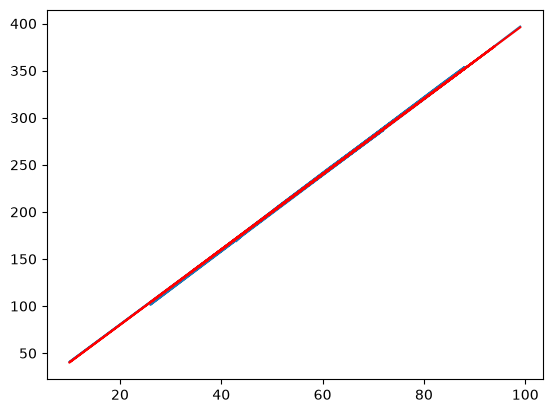

In [25]:
plt.plot(xtest,ytest)
plt.plot(xtest,ypred,color='red')

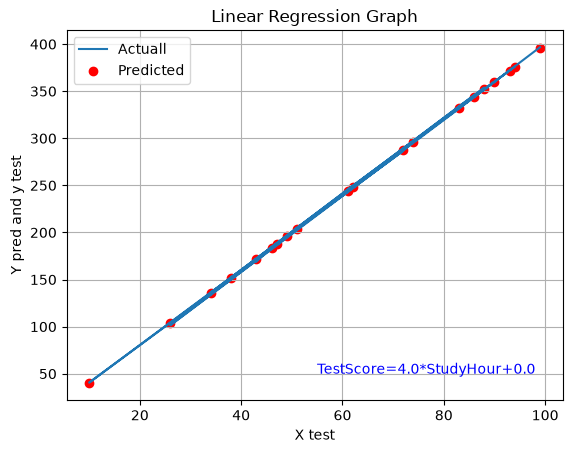

In [26]:
#test score = m × Study Hours + c
plt.plot(xtest,ytest,label="Actuall")
plt.scatter(xtest,ypred,color='red',label="Predicted")
equ=f"TestScore={cf.round(2)}*StudyHour+{intc.round(2)}"
plt.text(55,50,equ,c="b")
plt.title("Linear Regression Graph")
plt.xlabel("X test")
plt.ylabel("Y pred and y test")
plt.legend()
plt.grid(True)
plt.show()

In [27]:
#evaluate RSS
from sklearn import metrics
RSS=(np.sum(ytest-ypred)**2).round(2)
print("RSS:",RSS)
print("MAE",metrics.mean_absolute_error(ytest,ypred).round(2));
print("MSE",metrics.mean_squared_error(ytest,ypred).round(2));
print("RMSE",np.sqrt(metrics.mean_squared_error(ytest,ypred).round(2)));
TSS=np.sum((ytest-np.mean(ytest))**2).round(2)
print("TSS",TSS)
print("R2 value:",(1-(RSS/TSS)).round(2))

RSS: 1.44


AttributeError: 'float' object has no attribute 'round'

In [ ]:
#from a new dataframe studyhour , ytest ,y predict
df2=pd.DataFrame({"StudyHour":xtest[:,0],"Y-Actual":ytest.round(2),"Y-Predict":ypred.round(2)})
df2=df2.reset_index(drop=True)
df2

,StudyHour,Y-Actual,Y-Predict
0,67,269.57,265.75
1,38,172.82,150.50
2,9,17.04,35.25
3,67,248.02,265.75
4,25,61.83,98.84
5,46,187.38,182.29
6,73,310.62,289.60
7,41,165.07,162.42
8,27,92.30,106.78
9,2,7.46,7.43


In [ ]:
#save df2 to linearRegression_output.csv
df2.to_csv('linearRegression_output.csv')